# Is curvature worth adding to gpu_corrcal?

**Question.** Would curvature information (the Fisher matrix or Hessian of the CorrCal negative log-likelihood) make calibration converge in meaningfully less time than the current nonlinear conjugate-gradient (CG) solve?

**Approach.** Everything runs on the float64 CPU CorrCal reference, so the curvature and iteration counts are free of float32 effects; the GPU computes the same likelihood and gradient (validated in `calibration_simulation_chord_layout.ipynb`), so iteration counts carry over. The simulated problem is built by `build_problem` in the benchmark script, the same setup as the validation notebook.

1. **Curvature spectrum.** Compute the curvature $H$ at the optimum and identify which directions are poorly conditioned.
2. **Preconditioning ceiling.** Run CG with no preconditioner, with $\mathrm{diag}(H)$ (the "diagonal curvature" option), and with the full $H$ (the ideal, unaffordable case). Count likelihood and gradient calls to reach the noise floor.
3. **Regimes.** Repeat the convergence count at low SNR and with a single source in $\Sigma$ (no bright source in the beam).

**Phase prior off.** CorrCal's phase prior is $(\overline{\arg g_a})^2/\sigma_\phi^2$ with $\arg$ from `arctan2`, which jumps by $2\pi/N_{\rm ant}$ whenever one antenna's phase crosses $\pm\pi$. The likelihood is then discontinuous, CG can stop pinned against the jump, and finite-difference curvature across it is meaningless (this happened at 12x12 with `phs_norm = 0.1`). This study sets `phs_norm = inf`. The prior only fixes the overall phase, which is an exact degeneracy and is removed from the error metric anyway; without it the overall phase is an exact zero mode of $H$, excluded from the checks below. A wrap-safe prior (e.g. on the phase of $\sum_a g_a/|g_a|$) would fix this in CorrCal and gpu_corrcal.

**Metric.** Calibration accuracy is the rms complex fractional gain error against the true gains with the degenerate modes removed (overall amplitude, overall phase, phase gradient). The *noise floor* is that error at the exact optimum of the likelihood; "reached the floor" means within 5% of it. Cost is counted in likelihood + gradient calls, since per-call time is the same for every method.

In [1]:
import time
import types
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

warnings.filterwarnings("ignore")

try:                                   # the benchmark script, in this folder
    import calibration_benchmark as bc
except ImportError:
    import benchmark_calibration as bc

BASE_CFG = dict(freq=600e6, dish_d=6.0, min_group_size=5, max_za_deg=40.0, t_mean=30.0, t_rms=5.0,
                n_src_total=2000, s_min=1.0, src_slope=2.5, amp_jitter=0.1, init_amp_err=0.1,
                init_phs_err=0.1, phs_norm=np.inf, nside_max=1024, seed=1, chord_csv=bc.DEFAULT_CSV)

INITS = {"easy (10%, 0.1 rad)": (0.10, 0.1),       # amplitude, phase error of the initial guess
         "hard (30%, 0.5 rad)": (0.30, 0.5)}
TARGET_TOL = 0.05                                    # "reached the floor" = within 5% of it

## Helpers

- `make_problem` builds the simulated data and model covariance (`bc.build_problem`) and the CPU likelihood and gradient (`bc.build_objective`).
- `curvature` computes $H_{ij} = \partial^2 f / \partial x_i \partial x_j$ at $x^*$ by central differences of the analytic gradient, $H_{:,j} = [\nabla f(x^*+h e_j) - \nabla f(x^*-h e_j)]/2h$, then symmetrizes.
- `reference_optimum` finds the exact optimum $x^*$: long float64 CG solves from the true gains, restarted until the solution stops moving, then a check that $H$ there is positive semidefinite (only the exact overall-phase zero mode may be ~0). If an eigenvalue is negative, it moves to the lowest $f$ along that eigenvector and solves again.
- `initial_guess` perturbs the true gains as in the validation notebook.
- `run_cg` runs scipy CG in rescaled variables $y$, which is how a fixed preconditioner $M$ enters nonlinear CG: with $x = T y$, CG on $\phi(y) = f(Ty)$ uses gradient $T^T\nabla f$.
  - `plain`: $T = I$.
  - `diag`: $T = \mathrm{diag}(H)^{-1/2}$ (Jacobi).
  - `full`: $T = V\Lambda^{-1/2}$ with $H = V\Lambda V^T$ (ideal preconditioner from the exact curvature at the optimum). The exact overall-phase zero mode is given the curvature of the softest real mode, since otherwise it would be stretched without bound.

  It records the call count and the iterate after every CG iteration. A run whose step leaves the region where $C$ is positive definite is reported as diverged.
- `calls_to_floor` returns the first iteration and call count at which the non-degenerate error is within `TARGET_TOL` of the floor.

In [2]:
def make_problem(layout, snr=1e4, n_src_cal=5):
    cfg = types.SimpleNamespace(**BASE_CFG, snr=snr, n_src_cal=n_src_cal)
    P = bc.build_problem(layout, cfg, np.random.default_rng(1))
    fun, jac = bc.build_objective("cpu", P, cfg)
    return P, fun, jac


def curvature(jac, x, h=1e-6):
    n = x.size
    H = np.empty((n, n))
    for j in range(n):
        e = np.zeros(n)
        e[j] = h
        H[:, j] = (jac(x + e) - jac(x - e)) / (2 * h)
    return 0.5 * (H + H.T)


def cg_until_stationary(fun, jac, x, max_restarts=5):
    for _ in range(max_restarts):
        x_new = minimize(fun, x, jac=jac, method="CG", options={"maxiter": 5000, "gtol": 1e-9}).x
        moved = np.abs(x_new - x).max()
        x = x_new
        if moved < 1e-10:
            break
    return x


def reference_optimum(fun, jac, P, max_escapes=5, with_curvature=False):
    # Exact optimum x*, verified to be a minimum (curvature positive definite). CG can stop where the
    # curvature is negative along a degenerate (curved) direction; then line-search f along that
    # eigenvector, move to the lowest point, and solve again.
    x = cg_until_stationary(fun, jac, bc.split_re_im(P["true_gains"]))
    for _ in range(max_escapes):
        H = curvature(jac, x)
        lam, V = np.linalg.eigh(H)
        if lam[0] > -1e-6 * lam[-1]:     # positive semidefinite: only the exact overall-phase zero mode
            return (x, H) if with_curvature else x
        v = V[:, 0]
        ts = np.linspace(-3, 3, 121)
        x = x + ts[np.argmin([fun(x + t * v) for t in ts])] * v
        x = cg_until_stationary(fun, jac, x)
    raise RuntimeError(f"no positive-definite optimum found (smallest eigenvalue {lam[0]:.3g})")


def initial_guess(P, amp_err, phs_err, seed=7):
    rng = np.random.default_rng(seed)
    g = P["true_gains"]
    g0 = np.abs(g) * rng.normal(1, amp_err, P["n_ant"]) * np.exp(1j * (np.angle(g) + rng.normal(0, phs_err, P["n_ant"])))
    return bc.split_re_im(g0)


def make_transforms(H):
    d = np.sqrt(np.diag(H))
    # Full preconditioner H = V diag(lam) V^T. The exact overall-phase zero mode (lam ~ 0) would be
    # stretched without bound, so it gets the curvature of the softest real mode instead.
    lam, V = np.linalg.eigh(H)
    if abs(lam[0]) < 1e-6 * lam[-1]:
        lam[0] = lam[1]
    s = np.sqrt(lam)
    return {   # (y -> x, grad_x -> grad_y, x -> y), with x = T y
        "plain": (lambda y: y, lambda g: g, lambda x: x),
        "diag": (lambda y: y / d, lambda g: g / d, lambda x: x * d),
        "full": (lambda y: V @ (y / s), lambda g: (V.T @ g) / s, lambda x: s * (V.T @ x)),
    }


def run_cg(fun, jac, x0, transform, maxiter=3000):
    to_x, to_gy, to_y = transform
    calls = [0]

    def f(y):
        calls[0] += 1
        return fun(to_x(y))

    def g(y):
        calls[0] += 1
        return to_gy(jac(to_x(y)))

    hist = [(0, x0.copy())]
    try:
        res = minimize(f, to_y(x0), jac=g, method="CG", options={"maxiter": maxiter, "gtol": 1e-12},
                       callback=lambda yk: hist.append((calls[0], to_x(yk))))
        nit = res.nit
    except np.linalg.LinAlgError:          # a step left the region where C is positive definite
        nit = f"diverged at {len(hist) - 1}"
    return hist, nit


def nd_error(x, P):
    return bc.nondegenerate_error(x, P["true_gains"], P["antpos"])


def calls_to_floor(hist, P, floor):
    for it, (c, x) in enumerate(hist):
        if nd_error(x, P) <= (1 + TARGET_TOL) * floor:
            return it, c
    return None, None

## 1. Curvature spectrum at the optimum

The eigenvalues of $H$ set how hard the problem is for a first-order method: CG's progress along each eigendirection is limited by the ratio of the largest to the smallest eigenvalue (the condition number).

The soft directions are compared with the four analytically known degenerate directions of the gains $g_a$, written as Re/Im parameter vectors at $x^*$:
- overall amplitude, $\delta g_a = g_a$
- overall phase, $\delta g_a = i\,g_a$
- E and N phase gradient, $\delta g_a = i\,x_a g_a$ and $\delta g_a = i\,y_a g_a$

`overlap` is the fraction of an eigenvector's norm that lies in the span of these four vectors (1 means the eigenvector is a degenerate mode).

grid:8x8: 64 antennas, 128 parameters (3.3 s)
  eigenvalues: max 7.73e+05; smallest = exact overall-phase zero mode (0.00043); condition number of the rest 3.17e+05
  6 smallest: [4.298e-04 2.441e+00 4.026e+00 4.359e+01 2.343e+05 2.542e+05]
  condition number of the non-degenerate block (eigenvalues 5 and up): 3.30
  overlap with degenerate modes: [1.00e+00 1.00e+00 1.00e+00 1.00e+00 1.39e-05 2.58e-07]
  diag(H): min 2.53e+05, max 6.37e+05, max/min = 2.52
  noise floor (non-degenerate error at x*): 2.993e-03


grid:12x12: 144 antennas, 288 parameters (14.0 s)
  eigenvalues: max 1.4e+06; smallest = exact overall-phase zero mode (-6.1e-05); condition number of the rest 1.18e+05
  6 smallest: [-6.081e-05  1.189e+01  1.759e+01  4.653e+01  3.715e+05  3.933e+05]
  condition number of the non-degenerate block (eigenvalues 5 and up): 3.77
  overlap with degenerate modes: [1.00e+00 1.00e+00 1.00e+00 1.00e+00 8.08e-07 1.82e-05]
  diag(H): min 4.63e+05, max 1.04e+06, max/min = 2.26
  noise floor (non-degenerate error at x*): 2.093e-03


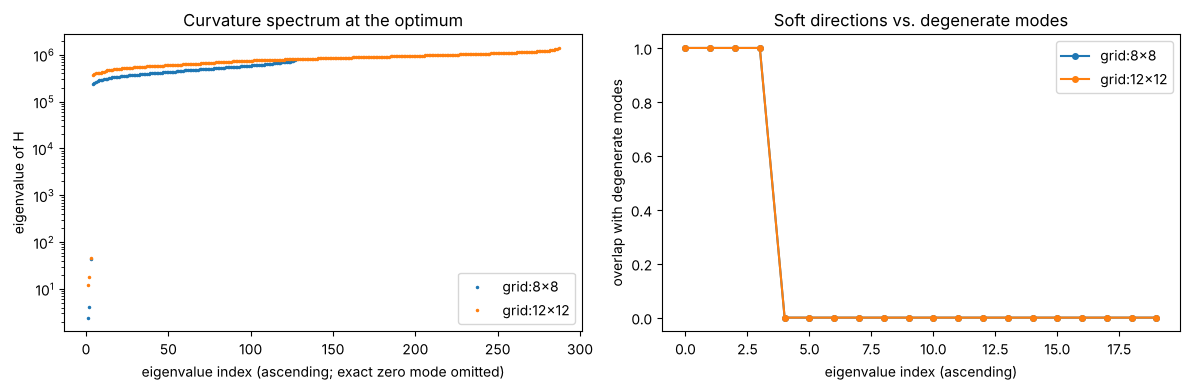

In [3]:
def degenerate_basis(x, antpos):
    g = x[0::2] + 1j * x[1::2]
    vecs = [g, 1j * g, 1j * antpos[:, 0] * g, 1j * antpos[:, 1] * g]
    B = np.column_stack([bc.split_re_im(v) for v in vecs])
    Q, _ = np.linalg.qr(B)
    return Q


studies = {}
for layout in ("grid:8x8", "grid:12x12"):
    t0 = time.perf_counter()
    P, fun, jac = make_problem(layout)
    x_star, H = reference_optimum(fun, jac, P, with_curvature=True)
    ev, V = np.linalg.eigh(H)
    Q = degenerate_basis(x_star, P["antpos"])
    overlap = np.linalg.norm(Q.T @ V, axis=0)
    studies[layout] = dict(P=P, fun=fun, jac=jac, x_star=x_star, H=H, ev=ev, overlap=overlap)
    d = np.diag(H)
    print(f"{layout}: {P['n_ant']} antennas, {2 * P['n_ant']} parameters ({time.perf_counter() - t0:.1f} s)")
    print(f"  eigenvalues: max {ev[-1]:.3g}; smallest = exact overall-phase zero mode ({ev[0]:.2g}); "
          f"condition number of the rest {ev[-1] / ev[1]:.2e}")
    print(f"  6 smallest: {np.array2string(ev[:6], precision=3)}")
    print(f"  condition number of the non-degenerate block (eigenvalues 5 and up): {ev[-1] / ev[4]:.2f}")
    print(f"  overlap with degenerate modes: {np.array2string(overlap[:6], precision=2)}")
    print(f"  diag(H): min {d.min():.3g}, max {d.max():.3g}, max/min = {d.max() / d.min():.2f}")
    print(f"  noise floor (non-degenerate error at x*): {nd_error(x_star, P):.3e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for layout, s in studies.items():
    axes[0].semilogy(np.arange(1, s["ev"].size), s["ev"][1:], ".", ms=3, label=layout)
    axes[1].plot(s["overlap"][:20], "o-", ms=4, label=layout)
axes[0].set_xlabel("eigenvalue index (ascending; exact zero mode omitted)"); axes[0].set_ylabel("eigenvalue of H"); axes[0].legend()
axes[0].set_title("Curvature spectrum at the optimum")
axes[1].set_xlabel("eigenvalue index (ascending)"); axes[1].set_ylabel("overlap with degenerate modes")
axes[1].set_title("Soft directions vs. degenerate modes"); axes[1].legend()
fig.tight_layout();

**Reading this.** The four smallest eigenvalues have eigenvectors lying entirely in the span of the degenerate modes (overlap 1.00): the exact overall-phase zero mode, and the overall amplitude and phase gradient, which are only weakly fixed by the sources in $\Sigma$. Above them the spectrum jumps by four to five decades, and the remaining eigenvalues span a factor of only 3–4. The non-degenerate problem, which sets the calibration accuracy, has a condition number of about 3–4. That is why CG reaches the noise floor in about 5 iterations.

The diagonal of $H$ varies by only a factor of about 2 across parameters. Every antenna on a filled grid is constrained by a similar set of baselines, so a Jacobi preconditioner rescales the problem very little. The soft directions are collective modes spanning all antennas, which a diagonal preconditioner cannot reach.

## 2. Preconditioning ceiling

For each array and initial guess, CG runs with each preconditioner. The table gives the CG iterations and likelihood + gradient calls needed to reach the noise floor. The `full` preconditioner uses the exact $H$ at the optimum, which no practical method has; it is included as the best case for a fixed curvature preconditioner.

In [4]:
rows = []
histories = {}
for layout, s in studies.items():
    P, fun, jac, x_star = s["P"], s["fun"], s["jac"], s["x_star"]
    floor = nd_error(x_star, P)
    transforms = make_transforms(s["H"])
    for init_name, (a_err, p_err) in INITS.items():
        x0 = initial_guess(P, a_err, p_err)
        for method, T in transforms.items():
            t0 = time.perf_counter()
            hist, nit = run_cg(fun, jac, x0, T)
            it, c = calls_to_floor(hist, P, floor)
            histories[layout, init_name, method] = hist
            rows.append((layout, init_name, method, it, c, nit, time.perf_counter() - t0))

print(f"{'array':>11} {'initial guess':>20} {'precond':>7} | {'iterations':>10} {'calls':>6} to noise floor | scipy nit")
for layout, init_name, method, it, c, nit, wall in rows:
    print(f"{layout:>11} {init_name:>20} {method:>7} | {str(it):>10} {str(c):>6}                | {nit}")

      array        initial guess precond | iterations  calls to noise floor | scipy nit
   grid:8x8  easy (10%, 0.1 rad)   plain |          5     20                | 361
   grid:8x8  easy (10%, 0.1 rad)    diag |          5     26                | 335
   grid:8x8  easy (10%, 0.1 rad)    full |        157    636                | 3000
   grid:8x8  hard (30%, 0.5 rad)   plain |          7     30                | 567
   grid:8x8  hard (30%, 0.5 rad)    diag |          6     28                | 299
   grid:8x8  hard (30%, 0.5 rad)    full |         85    396                | 899
 grid:12x12  easy (10%, 0.1 rad)   plain |          5     20                | 292
 grid:12x12  easy (10%, 0.1 rad)    diag |          5     24                | 106
 grid:12x12  easy (10%, 0.1 rad)    full |         38    192                | 148
 grid:12x12  hard (30%, 0.5 rad)   plain |          7     30                | 162
 grid:12x12  hard (30%, 0.5 rad)    diag |          7     28                | 95
 grid:12x1

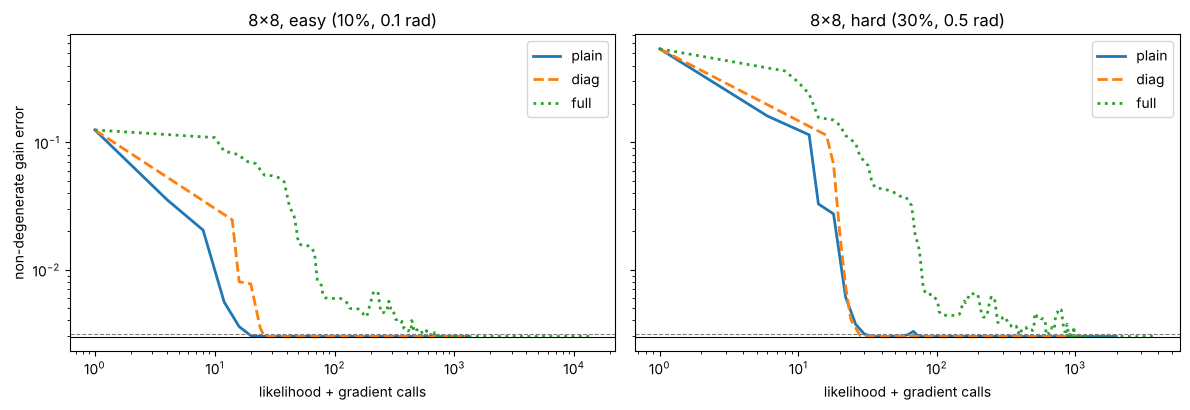

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, init_name in zip(axes, INITS):
    s = studies["grid:8x8"]
    floor = nd_error(s["x_star"], s["P"])
    for method, sty in (("plain", "-"), ("diag", "--"), ("full", ":")):
        hist = histories["grid:8x8", init_name, method]
        c = [h[0] for h in hist]
        e = [nd_error(h[1], s["P"]) for h in hist]
        ax.loglog(np.maximum(c, 1), e, sty, lw=2, label=method)
    ax.axhline(floor, color="k", lw=0.8)
    ax.axhline((1 + TARGET_TOL) * floor, color="0.5", lw=0.8, ls="--")
    ax.set_xlabel("likelihood + gradient calls"); ax.set_title(f"8x8, {init_name}")
    ax.legend()
axes[0].set_ylabel("non-degenerate gain error")
fig.tight_layout();

**Reading this.** Plain CG reaches the noise floor (black line) in about 5 iterations, 20–30 calls. The diagonal preconditioner changes nothing material, consistent with the near-uniform diagonal in section 1.

The full preconditioner is *slower*. The exact $H$ at the optimum stretches the soft (degenerate) directions by $\sqrt{\lambda_{\max}/\lambda_{\min}}$, several hundred times. In Re/Im coordinates those directions are curved (they are rotations and rescalings of the gains), so a step that is right for the local quadratic model overshoots off the curved valley and CG has to recover. A fixed curvature preconditioner is not a Newton method; one that recomputes curvature every step could do better, at a much higher cost per step.

**The ceiling.** Even a Newton method with free, exact curvature needs at least 2–3 steps from these initial guesses. Against 20–30 calls for plain CG, curvature could save at most about 2–3x in the best case. The exact Fisher diagonal costs about 100 gradient evaluations at 512 dishes, and Fisher-vector products cost about one gradient each. Either way the saving is gone.

## 3. Regimes: low SNR and no bright source

The same convergence count for plain CG, over SNR (autocorrelation over per-visibility noise) and over the number of sources in $\Sigma$. One source in $\Sigma$ means the model knows a single ~2 Jy source, against ~5 Jy rms of diffuse emission: no bright source in the beam. A new optimum and noise floor are computed for each case. `scipy nit` is the full scipy run, which keeps going to converge the degenerate modes.

In [6]:
regime_rows = []
for n_src in (1, 5):
    for snr in (10, 30, 100, 1e3, 1e4):
        P, fun, jac = make_problem("grid:8x8", snr=snr, n_src_cal=n_src)
        x_star = reference_optimum(fun, jac, P)
        floor = nd_error(x_star, P)
        out = []
        for init_name, (a_err, p_err) in INITS.items():
            x0 = initial_guess(P, a_err, p_err)
            hist, nit = run_cg(fun, jac, x0, (lambda y: y, lambda g: g, lambda x: x))
            out.append(calls_to_floor(hist, P, floor) + (nit, nd_error(x0, P)))
        regime_rows.append((n_src, snr, floor, out))

print(f"{'n_src':>5} {'SNR':>7} {'noise floor':>12} {'init error':>11} | {'easy: it, calls':>16} | {'hard: it, calls':>16} | scipy nit easy/hard")
for n_src, snr, floor, out in regime_rows:
    (it_e, c_e, nit_e, e0), (it_h, c_h, nit_h, _) = out
    print(f"{n_src:>5} {snr:>7g} {floor:>12.2e} {e0:>11.2e} | {str(it_e):>6} {str(c_e):>9} | "
          f"{str(it_h):>6} {str(c_h):>9} | {nit_e}/{nit_h}")

n_src     SNR  noise floor  init error |  easy: it, calls |  hard: it, calls | scipy nit easy/hard
    1      10     1.70e+00    1.25e-01 |      0         0 |      0         0 | 151/97
    1      30     1.66e+00    1.25e-01 |      0         0 |      0         0 | 516/150
    1     100     3.68e-01    1.25e-01 |      0         0 |      3        16 | 381/201
    1    1000     3.02e-02    1.25e-01 |      3        12 |      5        20 | 537/482
    1   10000     2.99e-03    1.25e-01 |      5        20 |      7        30 | 1328/1496
    5      10     1.73e+00    1.25e-01 |      0         0 |      0         0 | 166/258
    5      30     1.66e+00    1.25e-01 |      0         0 |      0         0 | 111/131
    5     100     3.67e-01    1.25e-01 |      0         0 |      3        16 | 60/67
    5    1000     3.03e-02    1.25e-01 |      3        12 |      5        20 | 199/232
    5   10000     2.99e-03    1.25e-01 |      5        20 |      7        30 | 361/567


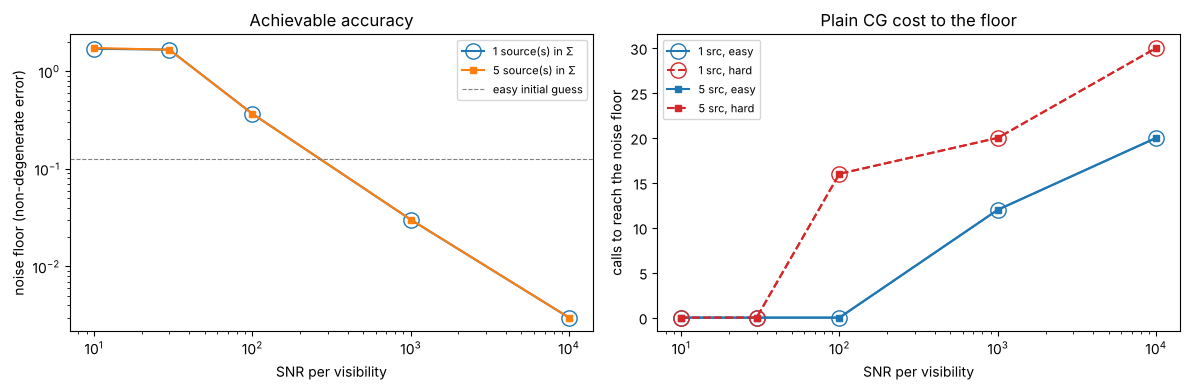

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# 1 source: large hollow markers; 5 sources: small filled markers (the two often coincide)
for n_src, mk, ms, mfc in ((1, "o", 11, "none"), (5, "s", 5, None)):
    sel = [r for r in regime_rows if r[0] == n_src]
    snr = [r[1] for r in sel]
    axes[0].loglog(snr, [r[2] for r in sel], mk + "-", ms=ms, mfc=mfc, label=f"{n_src} source(s) in Σ")
    for k, (init_name, ls, col) in enumerate(zip(INITS, ("-", "--"), ("C0", "C3"))):
        calls = [r[3][k][1] if r[3][k][1] is not None else np.nan for r in sel]
        axes[1].semilogx(snr, calls, mk + ls, color=col, ms=ms, mfc=mfc, label=f"{n_src} src, {init_name.split()[0]}")
axes[0].axhline(nd_error(initial_guess(studies["grid:8x8"]["P"], 0.1, 0.1), studies["grid:8x8"]["P"]),
                color="0.5", ls="--", lw=0.8, label="easy initial guess")
axes[0].set_xlabel("SNR per visibility"); axes[0].set_ylabel("noise floor (non-degenerate error)")
axes[0].set_title("Achievable accuracy"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("SNR per visibility"); axes[1].set_ylabel("calls to reach the noise floor")
axes[1].set_title("Plain CG cost to the floor"); axes[1].legend(fontsize=8)
fig.tight_layout();

**Reading this.**

- **No bright source.** Going from 5 sources in $\Sigma$ to 1 does not change the cost of reaching the noise floor. It changes the full scipy run, which is the degenerate modes converging differently. Without a bright source those modes are weakly fixed by the data themselves; curvature would converge them faster, but to values the data barely determine. Priors, joint fits over time (sources transiting at different times in a drift scan), or absolute calibration constrain them; curvature does not.
- **Low SNR.** The noise floor scales as 1/SNR. By SNR ~100 the best achievable error is already larger than the error of the initial guess, so CG has almost nothing to do, and below SNR ~30 a single snapshot, single channel solution is not informative at all. The remedy is more data per solution (averaging, joint time and frequency fits), not a better optimizer. Calibration SNR is set by the foregrounds, not the 21 cm signal; it drops only when integrations are shortened or channels narrowed.

## Conclusion

For the single snapshot, single channel CorrCal solve simulated here:

1. Plain nonlinear CG reaches the noise-limited gain accuracy in about 5 iterations (20–30 likelihood + gradient calls), on 64 and 144 antenna arrays, from easy and hard initial guesses, with 1 or 5 sources in $\Sigma$, and at every SNR where the solution is informative.
2. The problem's poor conditioning is confined to a few soft directions that coincide with the degenerate modes. A diagonal curvature preconditioner cannot reach them, and the ideal fixed preconditioner (exact $H$) is slower than none.
3. The best case for any curvature method is about a 2–3x reduction in calls, before paying for the curvature. The exact Fisher diagonal (~100 gradient evaluations at 512 dishes) or Fisher-vector products (~1 gradient each) consume that.

Curvature is therefore not worth adding for this problem now. It becomes relevant for **joint fits across frequency and time** with smoothness priors, which have many more coupled parameters, and for converging the degenerate modes if that is ever required, where the targeted tool is a low-rank treatment of the four known soft directions rather than a diagonal.

**Not tested here:** non-redundant data (dish position jitter, beam differences, mispointing) and phase errors near 1 rad.